# Portfólio 2 – Segmentação semântica vs. por instância
A semântica rotula pixels por classe (objeto/fundo); a de instância separa cada objeto individualmente (componentes conexos).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, morphology, measure, color, segmentation

## Funções
Pipeline: gaussiana → limiar (Otsu ou local) → limpeza morfológica → `label` para instâncias.

In [ ]:
def segmentar(img, claro_sobre_escuro=True, min_area=50, suavizar=1, raio=2, local=False, fundo=False):
    g = filters.gaussian(img, sigma=suavizar)
    if fundo:
        g = g - filters.gaussian(img, sigma=40)
    t = filters.threshold_local(g, 51, offset=0.02) if local else filters.threshold_otsu(g)
    mask = g > t if claro_sobre_escuro else g < t
    mask = morphology.remove_small_objects(mask, max_size=min_area)
    mask = morphology.remove_small_holes(mask, max_size=min_area)
    mask = morphology.opening(mask, morphology.disk(raio))
    inst = measure.label(mask, connectivity=1)
    return mask, inst

In [3]:
def plotar(img, mask, inst, nome):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title("Entrada")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title(f"Semântica (1 classe: {nome})")
    rgb = color.label2rgb(inst, bg_label=0, colors=plt.cm.nipy_spectral(np.random.default_rng(1).permutation(np.linspace(0.05, 0.95, max(inst.max(), 1)))))
    ax[2].imshow(rgb); ax[2].set_title(f"Instância (1 cor por {nome})")
    for a in ax: a.axis("off")
    plt.tight_layout()
    plt.show()

## Imagem 1: moedas (`data.coins`)

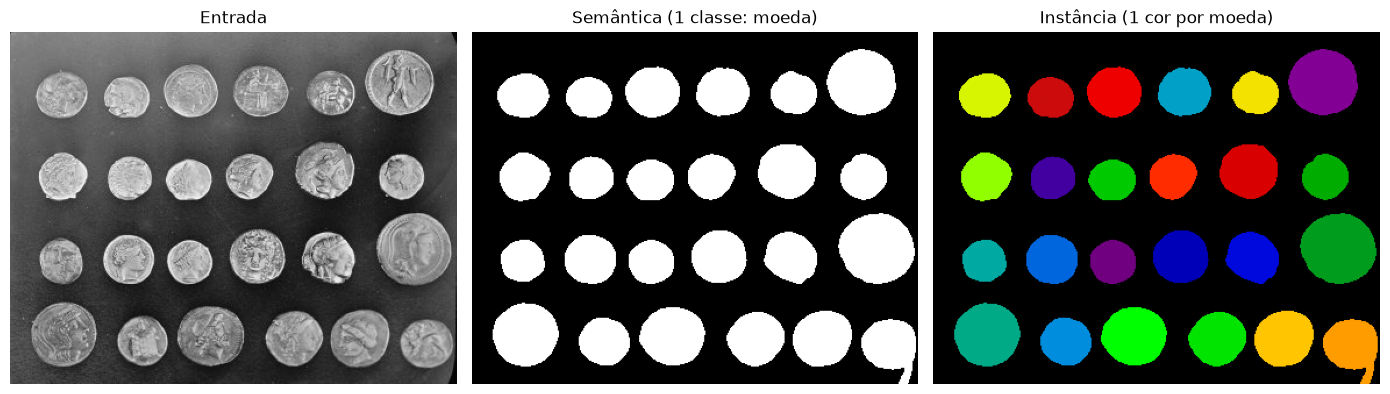

In [ ]:
img1 = data.coins()
m1, i1 = segmentar(img1, True, 200, 2, fundo=True)
plotar(img1, m1, i1, "moeda")

## Imagem 2: página de texto (`data.page`)

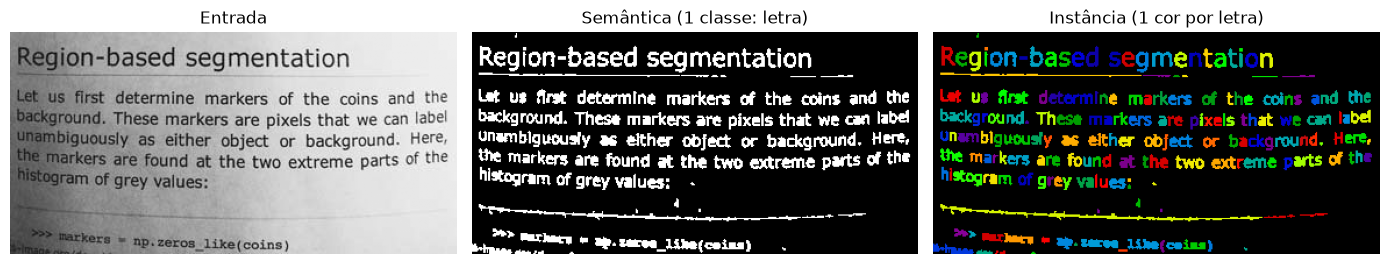

In [ ]:
img2 = data.page()
m2, i2 = segmentar(img2, False, 5, 0.5, raio=0, local=True)
plotar(img2, m2, i2, "letra")

In [6]:
for n, m, i in [("coins", m1, i1), ("texto", m2, i2)]:
    print(n, "objetos:", i.max(), "fração fg: %.3f" % m.mean())

coins objetos: 24 fração fg: 0.333
texto objetos: 186 fração fg: 0.173


## Análise
- **Moedas:** a semântica só diz "é moeda"; a de instância separa e conta cada uma (24), pois não se tocam. Subtraí o fundo por causa da iluminação desigual.
- **Texto:** a diferença quase some: letras coladas viram um só objeto e há ruído/iluminação irregular, então a contagem (186) não corresponde às letras reais.
- **Conclusão:** instância por componentes conexos só funciona bem com objetos separados; para objetos encostados seria preciso watershed.